In [60]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from models.extramlem import extraCNN
from utils.image_ops import normalise, sum_normalise


In [83]:
base = "/scratch/bggjem001/pet_datasets"

#Loading test images (min-max normalised for CNN input compatibility)
#test_ims_sn = np.load(f"{base}/datasets/images_test_sn.npy")
test_ims_sn = np.load(f"{base}/Ryan_Data/truth_blurred_4_182.npy")
test_ims_sn = test_ims_sn[None, ...]  
test_ims_sn = np.rot90(test_ims_sn, k=3, axes=(-2, -1)).copy()


mlem_test_raw = np.load(f"{base}/Ryan_Data/reco_4_182.npy")
mlem_test_raw = mlem_test_raw[None, ...] 
mlem_test_raw = np.rot90(mlem_test_raw, k=3, axes=(-2, -1)).copy()

(-0.5, 181.5, 181.5, -0.5)

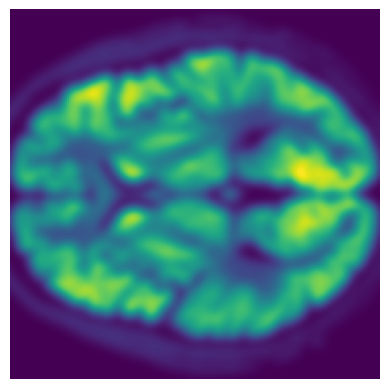

In [81]:
plt.imshow(test_ims_sn[0])
plt.axis("off")

(-0.5, 181.5, 181.5, -0.5)

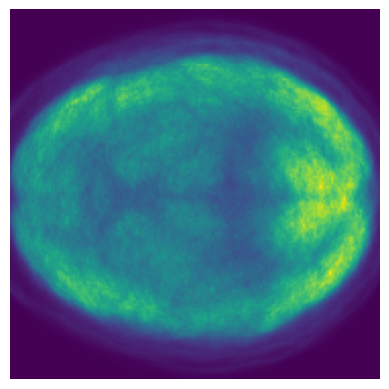

In [84]:
plt.imshow(mlem_test_raw[0])
plt.axis("off")

In [64]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

#Loading the trained extra-CNN model
model = extraCNN().to(device)
model.load_state_dict(torch.load(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/noisy3.0_extra9_sn1.pth", map_location=device))
model.eval()

extraCNN(
  (CNN_denoise): Sequential(
    (0): Conv2d(1, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): PReLU(num_parameters=1)
    (2): Conv2d(3, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

In [65]:
scale = 182*182

#Sum-normalised version of MLEM reconstructions for metric comparison
mlem_test_sn = np.array([sum_normalise(im) for im in mlem_test_raw])
mlem_test_scaled = mlem_test_sn * scale

In [66]:
with torch.no_grad():
    
    enhanced = []
    x = torch.from_numpy(mlem_test_scaled[0]).unsqueeze(0).unsqueeze(0).float().to(device)
    out = model(x)
    enhanced.append(out.squeeze().cpu().numpy())

enhanced = np.array(enhanced) / scale

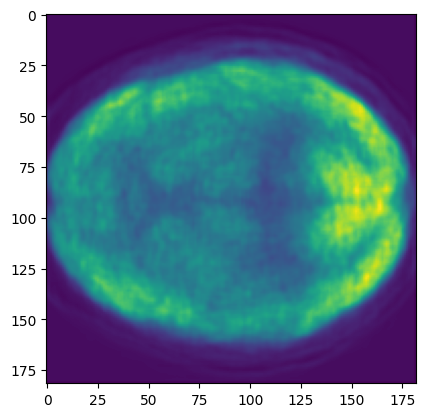

In [67]:
plt.imshow(enhanced[0])

In [68]:

mlem_n = mlem_test_sn[0] / mlem_test_sn.max()
cnn_n  = enhanced[0] / enhanced.max()
gt_n   = test_ims_sn[0]              # already [0,1]
# then metrics with data_range=1.0

global_dr = float(test_ims_sn.max() - test_ims_sn.min())

#NMSE
nmse_mlem = mean_squared_error(gt_n, mlem_n) / np.var(gt_n)

#Getting SSIM vals for normal MLEM
ssim_mlem = ssim(gt_n, mlem_n, data_range=global_dr)

#Getting PSNR vals for normal MLEM
psnr_mlem = psnr(gt_n, mlem_n, data_range=global_dr)

#NMSE
nmse_extra = mean_squared_error(gt_n, cnn_n) / np.var(gt_n)

#SSIM for extra-CNN
ssim_extra = ssim(gt_n, cnn_n, data_range=global_dr)

#PSNR for extra-CNN
psnr_extra = psnr(gt_n, cnn_n, data_range=global_dr)

print(psnr_extra, psnr_mlem)

19.19917740996469 19.363315968373474


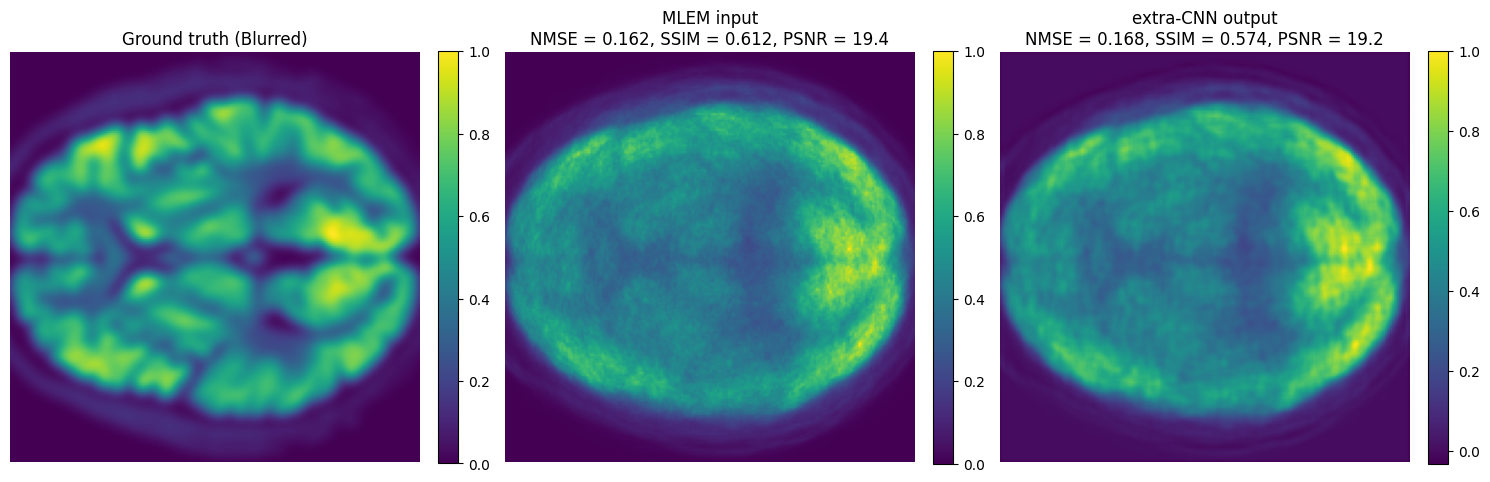

In [ ]:
fig2, ax2 = plt.subplots(1, 3, figsize=(15, 5))
panels = [
    (gt_n,    "Ground truth (Blurred)"),
    (mlem_n, f"MLEM input\nNMSE = {nmse_mlem:.3f}, SSIM = {ssim_mlem:.3f}, PSNR = {psnr_mlem:.1f}"),
    (cnn_n,   f"extra-CNN output\nNMSE = {nmse_extra:.3f}, SSIM = {ssim_extra:.3f}, PSNR = {psnr_extra:.1f}"),
]
for a, (img, title) in zip(ax2, panels):
    m = a.imshow(img)
    a.set_title(title)
    a.axis("off")
    fig2.colorbar(m, ax=a, fraction=0.046, pad=0.04)

plt.tight_layout()
#plt.savefig(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/Plots/ryan_slice_gt_input_output.png", dpi=300, bbox_inches="tight")
plt.show()

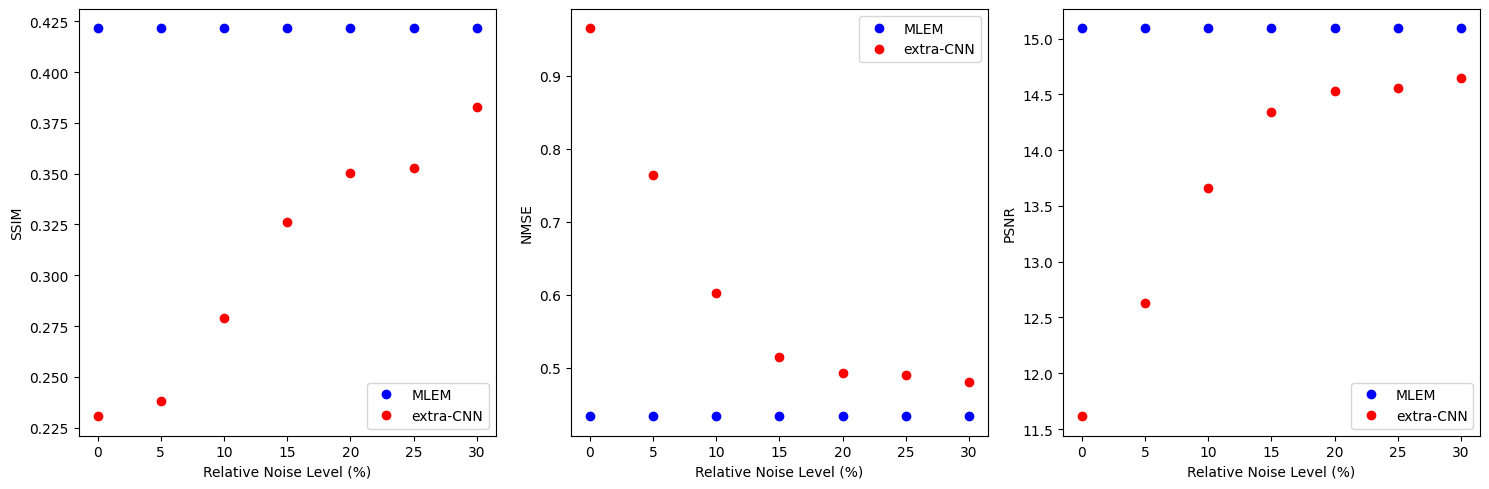

In [70]:
noise_levels = [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]

global_dr = float(test_ims_sn.max() - test_ims_sn.min())

idx = 0              # the single slice from Ryan
display_noise = 0    # which trained model's output to visualise (0 = clean)

ssim_mlem, ssim_extra = [], []
psnr_mlem, psnr_extra = [], []
nmse_mlem, nmse_extra = [], []

for noise in noise_levels:

    prefix = "clean" if noise == 0 else f"noisy{noise}"
    mlem_prefix = '' if noise == 0 else f"noisy{noise}_"

    scale = 182*182

    mlem_test_raw = np.load(f"{base}/Ryan_Data/reco_4_182.npy")
    mlem_test_raw = mlem_test_raw[None, ...] 
    mlem_test_raw = np.rot90(mlem_test_raw, k=1, axes=(-2, -1)).copy()

    #Sum-normalised version of MLEM reconstructions for metric comparison
    mlem_test_sn = np.array([sum_normalise(im) for im in mlem_test_raw])
    mlem_test_scaled = mlem_test_sn * scale

    #Loading the trained extra-CNN model
    model = extraCNN().to(device)
    model.load_state_dict(torch.load(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/model_weights/{prefix}_extra9_sn1.pth", map_location=device))
    model.eval()

    with torch.no_grad():
        enhanced = []
        x = torch.from_numpy(mlem_test_scaled[0]).unsqueeze(0).unsqueeze(0).float().to(device)
        out = model(x)
        enhanced.append(out.squeeze().cpu().numpy())

    enhanced = np.array(enhanced) / scale

    mlem_test_sn[0] = mlem_test_sn[0] / mlem_test_sn.max()
    enhanced[0]  = enhanced[0] / enhanced.max()
    test_ims_sn[0]   = test_ims_sn[0]

    #NMSE
    nmse_vals =mean_squared_error(test_ims_sn[0], mlem_test_sn[0]) / np.var(test_ims_sn[0])
    nmse_mlem.append(nmse_vals)

    #Getting SSIM vals for normal MLEM
    
    
    ssim_vals=ssim(test_ims_sn[0], mlem_test_sn[0], data_range=global_dr)

    ssim_mlem.append(ssim_vals)

    #Getting PSNR vals for normal MLEM
    
    psnr_vals=psnr(test_ims_sn[0], mlem_test_sn[0], data_range=global_dr)

    psnr_mlem.append(psnr_vals)

    #NMSE
    nmse_vals = mean_squared_error(test_ims_sn[0], enhanced[0]) / np.var(test_ims_sn[0])
    nmse_extra.append(nmse_vals)

    #SSIM for extra-CNN
   
    ssim_vals=ssim(test_ims_sn[0], enhanced[0], data_range=global_dr)

    ssim_extra.append(ssim_vals)

    #PSNR for extra-CNN
    psnr_vals = psnr(test_ims_sn[0], enhanced[0], data_range=global_dr)

    psnr_extra.append(psnr_vals)

    del  mlem_test_raw, mlem_test_sn, mlem_test_scaled, enhanced, model
    torch.cuda.empty_cache()

noise_levels = np.array(noise_levels)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].plot(noise_levels*10, ssim_mlem, 'bo', label="MLEM")
axes[0].plot(noise_levels*10, ssim_extra, 'ro', label="extra-CNN")
axes[0].set_xlabel("Relative Noise Level (%)")
axes[0].set_ylabel("SSIM")
axes[0].legend()

axes[1].plot(noise_levels*10, nmse_mlem, 'bo', label="MLEM")
axes[1].plot(noise_levels*10, nmse_extra, 'ro', label="extra-CNN")
axes[1].set_xlabel("Relative Noise Level (%)")
axes[1].set_ylabel("NMSE")
axes[1].legend()

axes[2].plot(noise_levels*10, psnr_mlem, 'bo', label="MLEM")
axes[2].plot(noise_levels*10, psnr_extra, 'ro', label="extra-CNN")
axes[2].set_xlabel("Relative Noise Level (%)")
axes[2].set_ylabel("PSNR")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"/scratch/bggjem001/picoPET-sim/Final_Im_Workflow/Plots/metrics_vs_noise_ryan.png", dpi=300, bbox_inches='tight')
plt.show()

In [85]:
mlem_test = np.load(f"{base}/datasets/images_train_sn.npy")

(-0.5, 181.5, 181.5, -0.5)

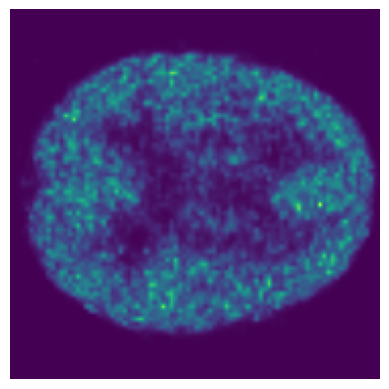

In [88]:
plt.imshow(mlem_test[25])
plt.axis("off")